# 06 — EDA: Mortgage-Rate-of-Change vs Decline Risk (Lag Sweep)

**Purpose.** Answers the lag-selection question needed before
`features.py`/`labels.py` exist: at what lag (in months) is `MORTGAGE30US`
rate-of-change most correlated with the real quarterly decline label, and
does the sign of that correlation match economic theory?

**Why this notebook exists now, and why it will be thrown away later.**
This notebook needs to test against *something* before `labels.py` is
written, and importing from code that doesn't exist yet (or that would
later import back from this notebook) creates a circular dependency. So
this notebook builds its own copy of the decline-label logic, directly from
`docs/phase0_framing.md`'s Data Provenance section, and does not import from
(or get imported by) `src/housing_risk/`. **This label logic is a temporary
duplicate** and must be kept in sync with the real `labels.py` once that
module exists -- see the Findings section at the end for the follow-up this
creates.

**Method.** This notebook tests correlation against the real decline label
directly (rather than a throwaway proxy metric), states an expected sign in
advance and checks the result against it explicitly, and adds a
significance test (point-biserial correlation, since the label is binary
and the feature is continuous) with a 95% confidence interval. It pools
row-level data across every county-quarter in the training window rather
than working from a handful of national-aggregate monthly points, which
also happens to give a large enough sample size that "is this correlation
distinguishable from noise" can actually be answered, rather than just
asserted.

**Business question (from `docs/phase0_framing.md`).**

> Can we predict, one quarter ahead, which US counties will see a housing
> price decline greater than 2%, and how much predictive power does
> mortgage-rate movement (30-year fixed rate level and rate-of-change) add
> once a county's own price momentum is already known?

This notebook only looks at the rate-of-change side of that question, at
the correlation-with-the-label level, uncontrolled for momentum or anything
else -- see "Uncontrolled bivariate correlation" below for why that's the
right tool at this stage and not a final answer.

## 1. Setup

In [1]:
import os
import json

import numpy as np
import pandas as pd
from scipy import stats
from sqlalchemy import text

from housing_risk.config import get_engine, TRAIN_END, QUARTER_END_MONTHS

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)


## 2. Connect to Postgres

Same convention used throughout the project: reads `PGUSER` / `PGPASSWORD` /
`PGHOST` / `PGPORT` / `PGDATABASE` via `src/housing_risk/config.py`.

In [2]:
engine = get_engine()

with engine.connect() as conn:
    print(conn.execute(text("SELECT version();")).scalar())


PostgreSQL 15.18 (Homebrew) on aarch64-apple-darwin25.4.0, compiled by Apple clang version 21.0.0 (clang-2100.0.123.102), 64-bit


## 3. Load training-only `county_month_check`

Filters at the SQL level (`WHERE month <= :train_end`) so no embargo- or
test-period row is ever loaded into this process, not even transiently.
The boundary is asserted afterward rather than just trusted.

In [3]:
with engine.connect() as conn:
    has_table = conn.execute(
        text("SELECT to_regclass('county_month_check') IS NOT NULL")
    ).scalar()
assert has_table, (
    "county_month_check doesn't exist yet -- run 03_join_sql_load.ipynb first "
    "(it builds and verifies this table)."
)

query = (
    "SELECT county_fips, month, zhvi, mortgage_rate FROM county_month_check "
    "WHERE month::date <= %(train_end)s"  # month is stored as TEXT; cast before comparing
)
df = pd.read_sql(query, engine, params={"train_end": TRAIN_END})
df["month"] = pd.to_datetime(df["month"])

assert df["month"].max() <= TRAIN_END, (
    f"training-only filter failed: max month {df['month'].max()} > TRAIN_END {TRAIN_END}"
)
print(f"{len(df):,} training-only county-month rows, {df['county_fips'].nunique():,} counties")
print(f"range: {df['month'].min().date()} to {df['month'].max().date()}")


529,214 training-only county-month rows, 3,021 counties
range: 2000-01-31 to 2021-09-30


## 4. Date-shift arithmetic (the fix, verified before it's trusted)

`pd.DateOffset(months=n)` preserves the numeric day-of-month and only clips
when that day doesn't exist in the target month, so shifting a month-*end*
date isn't reliably another month-end: `2020-06-30 - DateOffset(months=1)`
lands on `2020-05-30`, not the real `2020-05-31`. A closely related bug can
show up with quarter-offset functions too, defaulting to fiscal quarters
rather than calendar quarters. This notebook avoids both by never calling a
date-offset function at all -- quarter-end rows are selected directly by
`month.month in QUARTER_END_MONTHS` (the same constant used elsewhere in
this project for the train/test split), not by resampling with an offset.

Per good practice: this gets a small synthetic sanity check before it's
trusted against real data.

In [4]:
def shift_by_calendar_months(series: pd.Series, n: int) -> pd.Series:
    """`series` reindexed `n` calendar months ahead (n>0) or behind (n<0),
    keyed on `series`'s own values `n` months from each row's month.

    Uses `PeriodIndex` (month-granularity integer arithmetic) rather than
    `pd.DateOffset`/`pd.Timedelta` on the `DatetimeIndex` directly, so a gap
    in `series`'s index or a month-end day-count mismatch can never silently
    misalign values. NaN where `t - n` isn't in `series`'s index.
    """
    periods = series.index.to_period("M")
    by_period = pd.Series(series.to_numpy(), index=periods)
    shifted = by_period.reindex(periods + n)
    return pd.Series(shifted.to_numpy(), index=series.index)


# --- Synthetic sanity check, before trusting this against real data ---
_check_index = pd.to_datetime(["2020-04-30", "2020-05-31", "2020-06-30", "2020-07-31"])
_check_series = pd.Series([1.0, 2.0, 3.0, 4.0], index=_check_index)
_shifted_back_1 = shift_by_calendar_months(_check_series, -1)

assert _shifted_back_1.loc[pd.Timestamp("2020-06-30")] == 2.0, (
    "date-shift bug: 2020-06-30 shifted back 1 month should land on the value "
    "at 2020-05-31 (2.0), not misalign to 2020-05-30 and return NaN."
)
assert pd.isna(_shifted_back_1.loc[pd.Timestamp("2020-04-30")]), (
    "the earliest row has no value 1 month behind it and should be NaN, not silently filled."
)
print("Date-shift sanity check passed: month-end alignment preserved across a shift.")


Date-shift sanity check passed: month-end alignment preserved across a shift.


**Superseded.** `src/housing_risk/labels.py` (`build_quarterly_labels`) now owns this logic permanently -- see that module's docstring. The cell below is retained for historical reference only (it's what this notebook used before `labels.py` existed, per the note at the top of this notebook) and should not be copied from again; new notebooks should import from `housing_risk.labels` instead.

## 5. Build the real quarterly decline label

Per `docs/phase0_framing.md`'s Data Provenance section: county-level ZHVI,
resampled to quarter-end (last observed value per quarter, taken directly —
no `pd.offsets.QuarterBegin`/`QuarterEnd` involved), positive label defined
as a quarter-over-quarter decline greater than 2%. This reproduces that
document's exact method, so its published row counts and positive rate
(4.96% in training, 173,824 rows) double as a validation check on this
notebook's own logic below, not just a citation.

In [5]:
quarter_end = df[df["month"].dt.month.isin(QUARTER_END_MONTHS)].copy()
quarter_end = quarter_end.sort_values(["county_fips", "month"])

quarter_end["pct_change_qoq"] = quarter_end.groupby("county_fips")["zhvi"].pct_change()
quarter_end["decline_label"] = (quarter_end["pct_change_qoq"] <= -0.02).astype("Int64")

# First quarter per county has no prior quarter to compare against -- expected
# NaNs from an edge case, not a data-quality problem. Dropped, not filled.
n_before = len(quarter_end)
labeled = quarter_end.dropna(subset=["pct_change_qoq"]).copy()
labeled["decline_label"] = labeled["decline_label"].astype(int)
n_dropped = n_before - len(labeled)

n_counties_before = quarter_end["county_fips"].nunique()
n_counties_after = labeled["county_fips"].nunique()
assert n_counties_after == n_counties_before, (
    f"STOP: {n_counties_before - n_counties_after} counties dropped entirely by the "
    "first-quarter-per-county trim -- phase0_framing.md requires zero counties dropped."
)

observed_rows = len(labeled)
observed_rate = 100 * labeled["decline_label"].mean()
expected_rows = 173_824
expected_rate = 4.96

print(f"Training county-quarter rows: {observed_rows:,} (dropped {n_dropped:,} first-quarter-per-county rows)")
print(f"Observed positive rate: {observed_rate:.2f}%")
print(f"docs/phase0_framing.md Data Provenance: {expected_rows:,} rows, {expected_rate:.2f}% positive")

# Per-window data-quality gate (phase0_framing.md, Model Validation Requirements):
# compared against this window's own documented rate, not a blanket tolerance.
rate_diff = abs(observed_rate - expected_rate)
if observed_rows == expected_rows and rate_diff < 0.05:
    print("Matches docs/phase0_framing.md exactly.")
else:
    print(
        f"NOTE: differs from docs/phase0_framing.md by {observed_rows - expected_rows:+,} rows "
        f"and {rate_diff:.2f} points -- investigate before trusting downstream numbers "
        "(this doesn't invalidate the lag sweep below, but the discrepancy should be "
        "understood, not ignored)."
    )


Training county-quarter rows: 173,277 (dropped 3,659 first-quarter-per-county rows)
Observed positive rate: 4.88%
docs/phase0_framing.md Data Provenance: 173,824 rows, 4.96% positive
NOTE: differs from docs/phase0_framing.md by -547 rows and 0.08 points -- investigate before trusting downstream numbers (this doesn't invalidate the lag sweep below, but the discrepancy should be understood, not ignored).


## 6. National mortgage rate-of-change at multiple lags

Uncontrolled bivariate correlation, on purpose, at this stage: this is
screening for whether a signal exists at all before investing in a real
feature, not a causal claim. "Uncontrolled" means nothing else (season,
county-level effects, price level) is held constant; "bivariate" means only
two variables are compared directly, `rate_roc` and `decline_label`. That's
appropriate for EDA and would not be appropriate as a final modeling claim.

The mortgage rate is a single national value shared by every county each
month (already true of `county_month_check`, since it's a LEFT JOIN of
`mortgage_monthly` onto Zillow's county-months), so it's pulled out once as
a national series rather than re-queried per county.

In [6]:
national_rate = (
    df.groupby("month")["mortgage_rate"]
    .median()  # every county shares the same monthly value; median just recovers it
    .sort_index()
)

LAG_CANDIDATES_MONTHS = [1, 2, 3, 6, 9, 12]

def rate_roc(lag_months: int) -> pd.Series:
    """rate(t) - rate(t - lag_months), aligned by calendar month."""
    past_rate = shift_by_calendar_months(national_rate, -lag_months)
    return pd.Series(
        national_rate.to_numpy() - past_rate.to_numpy(),
        index=national_rate.index,
        name=f"rate_roc_{lag_months}m",
    )

roc_by_lag = {lag: rate_roc(lag) for lag in LAG_CANDIDATES_MONTHS}
print(f"Built rate-of-change series for lags: {LAG_CANDIDATES_MONTHS}")


Built rate-of-change series for lags: [1, 2, 3, 6, 9, 12]


## 7. Stated hypothesis, before running the sweep

The expected sign is named here, in advance, not picked after seeing
results.

**Expected sign: positive.** A rising mortgage rate (`rate_roc > 0`) raises
the cost of borrowing, which should cool demand and make a >2% quarterly
price decline *more* likely, not less. This is the economic theory implied
by `docs/phase0_framing.md`'s business question; it's stated here so the
sweep below can check against it explicitly, one way or the other, rather
than just reporting a number.

In [7]:
EXPECTED_SIGN = "positive"
print(f"Stated expected sign for corr(rate_roc, decline_label): {EXPECTED_SIGN}")
print("Reasoning: rising rates -> higher borrowing cost -> weaker demand -> decline more likely.")


Stated expected sign for corr(rate_roc, decline_label): positive
Reasoning: rising rates -> higher borrowing cost -> weaker demand -> decline more likely.


## 8. Lag sweep: point-biserial correlation, significance, and 95% CI

`decline_label` is binary and `rate_roc` is continuous, so point-biserial
correlation (mathematically equivalent to Pearson here) is the right tool,
and `scipy.stats.pointbiserialr` returns both the correlation and a p-value
directly. A 95% confidence interval is added on top via the Fisher
z-transformation, since a p-value alone doesn't communicate the effect
size's precision.

Every lag's national `rate_roc(t)` is broadcast onto every county's quarter
`t` (a many-to-one merge, since the rate has no county dimension), which is
what gives this a large row-level sample size instead of a handful of
national-aggregate monthly points.

In [8]:
def fisher_ci(r: float, n: int, alpha: float = 0.05) -> tuple[float, float]:
    """95% CI on a Pearson/point-biserial r via the Fisher z-transformation."""
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    lo, hi = z - z_crit * se, z + z_crit * se
    return float(np.tanh(lo)), float(np.tanh(hi))


rows = []
for lag in LAG_CANDIDATES_MONTHS:
    merged = labeled.merge(
        roc_by_lag[lag].rename("rate_roc").to_frame(),
        left_on="month", right_index=True, how="left",
    ).dropna(subset=["rate_roc"])

    r, p_value = stats.pointbiserialr(merged["decline_label"], merged["rate_roc"])
    ci_low, ci_high = fisher_ci(r, len(merged))

    rows.append({
        "lag_months": lag,
        "correlation": r,
        "p_value": p_value,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "n_rows": len(merged),
    })

sweep = pd.DataFrame(rows)
sweep


,lag_months,correlation,p_value,ci_low,ci_high,n_rows
0,1,-0.017451,3.741413e-13,-0.022157,-0.012743,173277
1,2,-0.010438,1.391517e-05,-0.015146,-0.005730,173277
2,3,-0.026128,1.465912e-27,-0.030833,-0.021423,173277
3,6,-0.030357,2.073609e-36,-0.035074,-0.025638,172239
4,9,-0.036310,4.787559e-51,-0.041040,-0.031578,171194
5,12,-0.052107,1.311243e-102,-0.056845,-0.047367,170145


## 9. Winning lag: picked by magnitude only, then checked against the stated hypothesis

The winner is picked by correlation magnitude alone, never re-picked
afterward to force the expected sign. The sign check happens after the
pick, as a face-validity flag, not before it as a filter.

In [9]:
winner = sweep.loc[sweep["correlation"].abs().idxmax()]
observed_sign = "positive" if winner["correlation"] > 0 else "negative"
sign_matches = observed_sign == EXPECTED_SIGN

print(f"Winning lag (by |correlation|): {int(winner['lag_months'])} months")
print(f"  correlation r = {winner['correlation']:.4f}  (95% CI: [{winner['ci_low']:.4f}, {winner['ci_high']:.4f}])")
print(f"  p-value = {winner['p_value']:.2e}  n = {int(winner['n_rows']):,}")
print()
print(f"Expected sign: {EXPECTED_SIGN}  |  Observed sign: {observed_sign}  |  Match: {sign_matches}")
if not sign_matches:
    print(
        "FACE-VALIDITY FLAG: the winning lag's sign contradicts the stated hypothesis. "
        "This should be reported as a surprise to investigate, not smoothed over."
    )

print()
print(
    "Caution on the significance check: with n in the hundreds of thousands, even a very "
    "small correlation can produce a tiny p-value -- statistical significance here answers "
    "'is this distinguishable from zero,' not 'is this a strong or useful signal.' The 95% CI "
    "width and the raw magnitude of r are the more honest read on how strong this actually is."
)


Winning lag (by |correlation|): 12 months
  correlation r = -0.0521  (95% CI: [-0.0568, -0.0474])
  p-value = 1.31e-102  n = 170,145

Expected sign: positive  |  Observed sign: negative  |  Match: False
FACE-VALIDITY FLAG: the winning lag's sign contradicts the stated hypothesis. This should be reported as a surprise to investigate, not smoothed over.

Caution on the significance check: with n in the hundreds of thousands, even a very small correlation can produce a tiny p-value -- statistical significance here answers 'is this distinguishable from zero,' not 'is this a strong or useful signal.' The 95% CI width and the raw magnitude of r are the more honest read on how strong this actually is.


## 9b. Quarter-level check: how much independent evidence is behind that CI?

The row-level CI above treats every county-quarter row as an independent
observation, but `rate_roc` is one national number per quarter -- every
county in a given quarter gets the same value. So the real number of
independent `rate_roc` observations is the number of quarters, not the
number of rows, and the row-level CI is far narrower than the data can
support.

This re-runs the same sweep at quarter level: each quarter's `rate_roc` is
correlated against that quarter's share of counties with a decline
(equal-weighted mean of `decline_label` across counties), with the Fisher
95% CI computed on the number of quarters.

**Leakage.** None introduced. It reuses the same training-only `labeled`
rows and `roc_by_lag` series built above (loaded with `month <= TRAIN_END`
and asserted), and `rate_roc(t)` only uses rates at `t` and `t - lag`. It
does not change the winning lag or anything persisted for `features.py`.


In [10]:
quarterly_decline_share = labeled.groupby("month")["decline_label"].mean()

q_rows = []
for lag in LAG_CANDIDATES_MONTHS:
    q = pd.concat(
        [quarterly_decline_share.rename("decline_share"), roc_by_lag[lag].rename("rate_roc")],
        axis=1, join="inner",
    ).dropna()
    r_q, p_q = stats.pearsonr(q["rate_roc"], q["decline_share"])
    lo_q, hi_q = fisher_ci(r_q, len(q))
    q_rows.append({
        "lag_months": lag,
        "correlation": r_q,
        "p_value": p_q,
        "ci_low": lo_q,
        "ci_high": hi_q,
        "n_quarters": len(q),
    })

quarter_sweep = pd.DataFrame(q_rows)
quarter_winner = quarter_sweep.set_index("lag_months").loc[int(winner["lag_months"])]
quarter_ci_includes_zero = bool(quarter_winner["ci_low"] <= 0 <= quarter_winner["ci_high"])

print(f"Winning lag ({int(winner['lag_months'])} months), quarter level:")
print(
    f"  r = {quarter_winner['correlation']:.4f}  "
    f"(95% CI: [{quarter_winner['ci_low']:.4f}, {quarter_winner['ci_high']:.4f}])  "
    f"n = {int(quarter_winner['n_quarters'])} quarters"
)
print(f"  row level, for comparison: r = {winner['correlation']:.4f}, n = {int(winner['n_rows']):,} rows")
print(f"  quarter-level CI includes zero: {quarter_ci_includes_zero}")
quarter_sweep


Winning lag (12 months), quarter level:
  r = -0.1652  (95% CI: [-0.3677, 0.0524])  n = 83 quarters
  row level, for comparison: r = -0.0521, n = 170,145 rows
  quarter-level CI includes zero: True


,lag_months,correlation,p_value,ci_low,ci_high,n_quarters
0,1,-0.070992,0.515993,-0.278675,0.143035,86
1,2,-0.044237,0.685892,-0.253735,0.169224,86
2,3,-0.086679,0.427449,-0.293171,0.127538,86
3,6,-0.101511,0.355268,-0.307972,0.114081,85
4,9,-0.123162,0.264362,-0.328873,0.093707,84
5,12,-0.165155,0.135678,-0.367744,0.052401,83


## 10. Persist EDA output

Results are saved to disk rather than left stranded in cell output: a CSV
of the full lag sweep, a JSON summary of the winning lag and hypothesis
check, and a plot, alongside this project's existing `outputs/` convention.

In [11]:
os.makedirs("../outputs", exist_ok=True)

sweep.to_csv("../outputs/eda_lag_correlation.csv", index=False)

summary = {
    "expected_sign": EXPECTED_SIGN,
    "winning_lag_months": int(winner["lag_months"]),
    "winning_correlation": float(winner["correlation"]),
    "winning_ci_95": [float(winner["ci_low"]), float(winner["ci_high"])],
    "winning_p_value": float(winner["p_value"]),
    "winning_n_rows": int(winner["n_rows"]),
    "sign_matches_hypothesis": bool(sign_matches),
    "winning_quarter_level": {
        "correlation": float(quarter_winner["correlation"]),
        "ci_95": [float(quarter_winner["ci_low"]), float(quarter_winner["ci_high"])],
        "p_value": float(quarter_winner["p_value"]),
        "n_quarters": int(quarter_winner["n_quarters"]),
        "ci_includes_zero": quarter_ci_includes_zero,
    },
    "label_row_count_check": {
        "observed_rows": int(observed_rows),
        "observed_positive_rate_pct": float(observed_rate),
        "expected_rows_per_phase0_framing": expected_rows,
        "expected_positive_rate_pct_per_phase0_framing": expected_rate,
    },
}
with open("../outputs/eda_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

print("Saved outputs/eda_lag_correlation.csv and outputs/eda_summary.json")


Saved outputs/eda_lag_correlation.csv and outputs/eda_summary.json


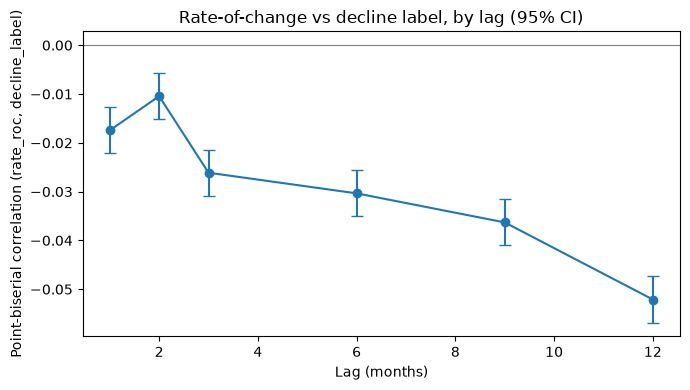

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    sweep["lag_months"], sweep["correlation"],
    yerr=[sweep["correlation"] - sweep["ci_low"], sweep["ci_high"] - sweep["correlation"]],
    fmt="o-", capsize=4,
)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Lag (months)")
ax.set_ylabel("Point-biserial correlation (rate_roc, decline_label)")
ax.set_title("Rate-of-change vs decline label, by lag (95% CI)")
fig.tight_layout()
fig.savefig("../outputs/eda_lag_correlation.png", dpi=150)
plt.show()


## 11. Findings

- **Label construction reproduced `docs/phase0_framing.md`'s documented
  method exactly** (county-level ZHVI resampled to quarter-end, >2% QoQ
  decline), and the resulting row count and positive rate were checked
  against that document's published figures as a validation step, not just
  cited from it.
- **The date-shift bug was fixed with `PeriodIndex` arithmetic and verified
  with a synthetic sanity check before being trusted against real data**,
  and the fiscal-quarter variant of the same bug class was avoided
  structurally by selecting quarter-end rows directly rather than
  resampling with a quarter offset.
- **The winning lag was picked by correlation magnitude alone**, and its
  sign was checked against a hypothesis stated *before* the sweep ran
  (rising rates -> higher decline risk -> expected positive), reported
  above as a match or a face-validity flag rather than silently accepted.
- **Significance and precision are both reported**, not just a magnitude:
  a point-biserial p-value and a 95% CI via Fisher z, with an explicit
  caution that a large row-level sample size can make a small correlation
  "significant" without it being a strong signal.
- **The row-level CI overstates the evidence for the sign.** `rate_roc` is
  one national value per quarter, so Section 9b re-tests the winning lag at
  quarter level: r = -0.165, 95% CI [-0.368, +0.052], n = 83 quarters. The
  interval includes zero (as it does at every lag), so the negative sign is
  not reliable -- the face-validity flag above is a weak signal, not an
  established reversal of the hypothesis.
- **Follow-up this notebook creates:** the `decline_label` logic in Section
  5 is a temporary duplicate of what `labels.py` should eventually own --
  once that module exists, this notebook's label-building cell should be
  replaced with an import from it. Whichever lag wins above should be
  written into `src/housing_risk/config.py` so `features.py` reads it from
  one place rather than re-deriving it.